In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Описание датасета

`age` - возраст пациента (int)

`sex` - пол пациента (категориальный)

`bmi` - индекс массы тела (float)

`children` - количество детей (int)

`smoker` - курит ли пациент (категориальный)

`region` - регион (категориальный)

`charges` - затраты, таргет для задачи регрессии (float)

In [2]:
df = pd.read_csv('insurance.csv')
df.head(10) 

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [3]:
y = df['charges']
X_raw = df.drop(columns=['charges'])
X = pd.get_dummies(X_raw, drop_first=True, dtype=float)

print(X.head(5))
print(X.shape)

   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0       0.0         1.0               0.0   
1   18  33.770         1       1.0         0.0               0.0   
2   28  33.000         3       1.0         0.0               0.0   
3   33  22.705         0       1.0         0.0               1.0   
4   32  28.880         0       1.0         0.0               1.0   

   region_southeast  region_southwest  
0               0.0               1.0  
1               1.0               0.0  
2               1.0               0.0  
3               0.0               0.0  
4               0.0               0.0  
(1338, 8)


Попробуем умножить вектор второго пациента на рандомный вектор весов

In [4]:
np.random.seed(42)

x_sample = X.iloc[0].to_numpy()
y_true = y.iloc[0]

w = np.array([4, 7, 2, 9, 15, -20, 3.5, 0])

y_pred = x_sample @ w

print("Вектор признаков второго пациента:")
print(x_sample)
print(f"Реальные расходы: ${y_true:.2f}")
print(f"Случайный вектор весов w:")
print(np.round(w, 2))

print(f"\nПредсказание модели: ${y_pred:.2f}")
print(f"Реальное значение:   ${y_true:.2f}")
print(f"Ошибка (разница):    ${y_true - y_pred:.2f}")
print(f"MSE:                 ${(y_true - y_pred)**2:.2f}")

Вектор признаков второго пациента:
[19.  27.9  0.   0.   1.   0.   0.   1. ]
Реальные расходы: $16884.92
Случайный вектор весов w:
[  4.    7.    2.    9.   15.  -20.    3.5   0. ]

Предсказание модели: $286.30
Реальное значение:   $16884.92
Ошибка (разница):    $16598.62
MSE:                 $275514318.69


## Описательные статистики данных

Изучим числовые признаки в нашем датасете

In [5]:
df['age'].describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [6]:
df['bmi'].describe()

count    1338.000000
mean       30.663397
std         6.098187
min        15.960000
25%        26.296250
50%        30.400000
75%        34.693750
max        53.130000
Name: bmi, dtype: float64

Можно заметить, что для признаков `age` и `bmi` среднее и медиана (50%) достаточно близки по значению

In [7]:
df['charges'].describe()

count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

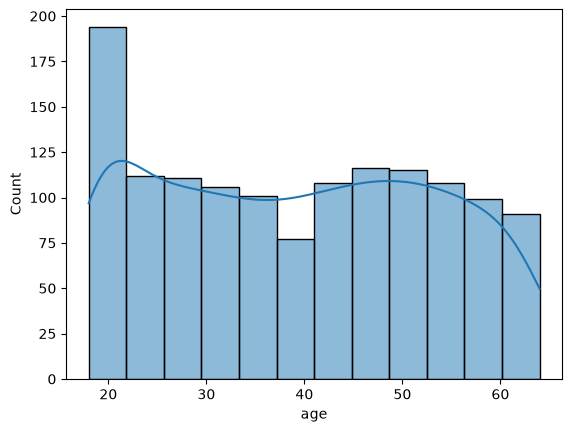

In [8]:
sns.histplot(df['age'], kde=True)

<Axes: xlabel='bmi', ylabel='Count'>

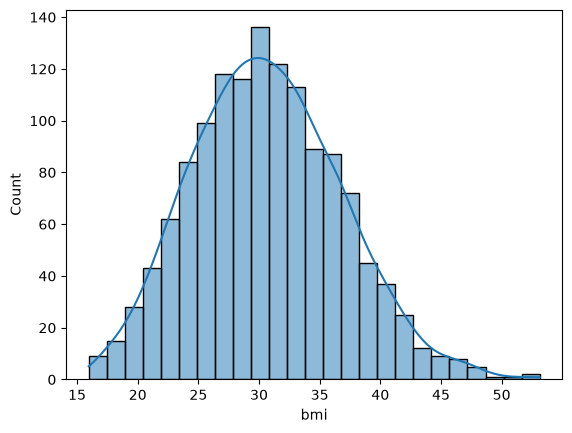

In [9]:
sns.histplot(df['bmi'], kde=True)

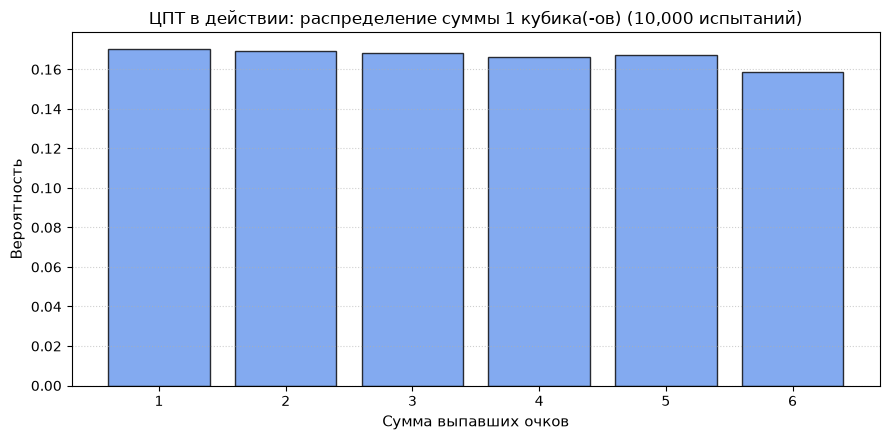

In [14]:
n_dice = 1
n_trials = 10000

rolls = np.random.randint(1, 7, size=(n_trials, n_dice))

sums = rolls.sum(axis=1)

unique_sums, counts = np.unique(sums, return_counts=True)
probabilities = counts / n_trials

plt.figure(figsize=(9, 4.5))
plt.bar(unique_sums, probabilities, width=0.8, color='cornflowerblue', edgecolor='black', alpha=0.8, label='Частота исходов')

if n_dice > 1:
    mu_theor = n_dice * 3.5
    var_theor = n_dice * (35 / 12)
    sigma_theor = np.sqrt(var_theor)
    
    x_grid = np.linspace(n_dice, 6 * n_dice, 300)
    y_norm = stats.norm.pdf(x_grid, mu_theor, sigma_theor)
    plt.plot(x_grid, y_norm, color='crimson', lw=2.5, label='Колокол Гаусса (теория ЦПТ)')
    plt.legend(fontsize=10)

plt.title(f'ЦПТ в действии: распределение суммы {n_dice} кубика(-ов) ({n_trials:,} испытаний)', fontsize=12)
plt.xlabel('Сумма выпавших очков', fontsize=11)
plt.ylabel('Вероятность', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

<Axes: xlabel='charges', ylabel='Count'>

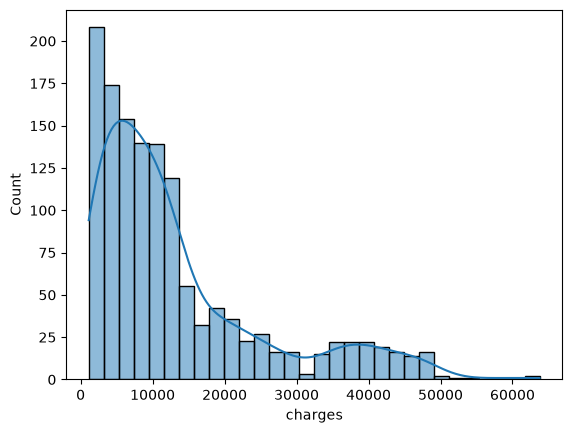

In [15]:
sns.histplot(df['charges'], kde=True)

## Обучение модели

Для обучения модели используется градиентный спуск: функция ошибки итеративно минимизируется путем смещения вектора весов в направлении антиградиента функции ошибки по всем весам

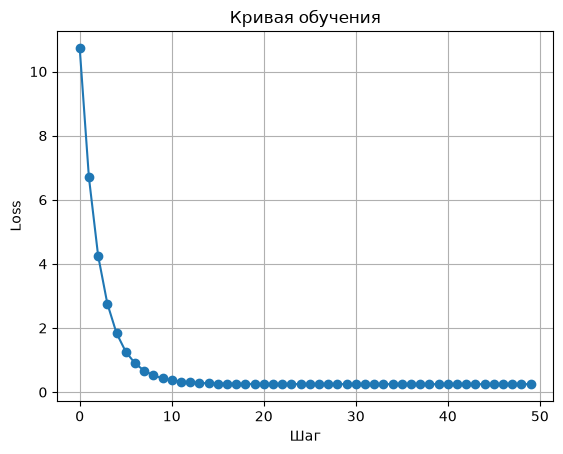

In [16]:
feature_names = ['bias'] + list(X.columns)

X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

y_mean = y.mean()
y_std = y.std()
y_scaled = (y - y_mean) / y_std

X_mat = np.c_[np.ones(X_scaled.shape[0]), X_scaled.to_numpy()]
y_vec = y_scaled.to_numpy()

w = np.random.randn(X_mat.shape[1])
 
lr = 0.1
n_steps = 50

losses = []

for i in range(n_steps):
    y_pred = X_mat @ w
    loss = np.mean((y_vec - y_pred)**2)
    losses.append(loss)

    grad = (2 / len(X_mat)) * (X_mat.T @ (y_pred - y_vec))
    w -= lr * grad

plt.plot(range(n_steps), losses, marker='o')
plt.title("Кривая обучения")
plt.xlabel('Шаг')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

Линейная модель со стандартизированными данными хорошо интерпретируема в плане важности признаков: чем больше вес по модулю тем выше его важность

Веса модели:
         Feature    Weight
      smoker_yes  0.794944
             age  0.297616
             bmi  0.172712
        children  0.047592
region_southeast -0.046941
region_southwest -0.042217
region_northwest -0.020470
        sex_male -0.005497
            bias -0.000008


/var/folders/_w/18vz4krx3cdbjcc_lmpp63g80000gn/T/ipykernel_74102/4032958633.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weights_df[weights_df['Feature'] != 'bias'], x='Weight', y='Feature', palette='vlag')


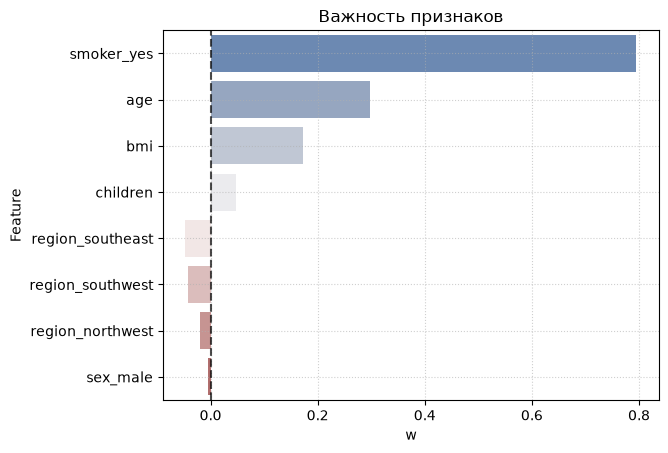

In [17]:
weights_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': w
}).sort_values(by='Weight', key=abs, ascending=False)

print("Веса модели:")
print(weights_df.to_string(index=False))

plt.Figure(figsize=(8, 4))
sns.barplot(data=weights_df[weights_df['Feature'] != 'bias'], x='Weight', y='Feature', palette='vlag')
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Важность признаков')
plt.xlabel('w')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Метрики

Оценим результаты обучения модели на тренировочной выборке

In [18]:
y_pred_real = y_pred * y_std + y_mean
y_real = df['charges'].to_numpy()

mae = np.mean(np.abs(y_real - y_pred_real))
mse = np.mean((y_real - y_pred_real)**2)
rmse = np.sqrt(mse)

print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')

MAE: 4174.89
MSE: 36513085.69
RMSE: 6042.61
